# Technical Issue Taxonomy — Feasibility Analysis
**ResolveX — M1: Project Research & Feasibility**

This notebook evaluates whether the six proposed Ubuntu/Linux issue categories can be supported by the Ask Ubuntu dataset.

Categories are matched using tag-based weak labels to assess coverage, class balance, category overlap, and answer availability.

## 1. Setup

Import dependencies and configure paths. Taxonomy definitions and the audit function are imported from `src/data/taxonomy.py`.

In [1]:
from pathlib import Path
import sys
import csv
import pandas as pd
import matplotlib.pyplot as plt

cwd = Path.cwd().resolve()
ROOT = next((folder for folder in (cwd, *cwd.parents)
             if (folder / "src" / "data" / "extraction.py").exists()), None)
if ROOT is None:
    raise FileNotFoundError("Open the notebook within the ResolveX repository")
sys.path.insert(0, str(ROOT / "src"))
RAW = ROOT / "data" / "raw" / "Posts.xml"
QUESTIONS = ROOT / "data" / "interim" / "questions.csv"
ANSWERS = ROOT / "data" / "interim" / "answers.csv"

from data.taxonomy import TAXONOMY, audit_questions
if not QUESTIONS.exists():
    raise FileNotFoundError("Missing questions.csv; run extraction first")

## 2. Taxonomy Definitions

Display the six technical issue categories and their associated tags.

Tag selection is a methodological assumption; these labels are not verified ground truth.

In [2]:
display(pd.DataFrame([{"Category": name, "Tag Count": len(tags),
                       "Selected Tags": ", ".join(sorted(tags))}
                      for name, tags in TAXONOMY.items()]))

,Category,Tag Count,Selected Tags
0,Network & Connectivity,14,"bluetooth, broadband, connection, dns, etherne..."
1,Boot & Startup,12,"bios, boot, boot-repair, dual-boot, grub, grub..."
2,Software & Packages,13,"apt, apt-get, dependencies, dpkg, installation..."
3,Hardware & Drivers,16,"amd-graphics, audio, display, drivers, gpu, gr..."
4,Storage & Filesystems,14,"data-recovery, disk, disk-usage, ext4, externa..."
5,Access & Permissions,11,"authentication, file-permissions, login, owner..."


## 3. Coverage Audit

Stream the question CSV and classify each question as single-category, multi-category, or unmatched based on its tags.

In [3]:
with QUESTIONS.open(encoding="utf-8", newline="") as handle:
    result = audit_questions(csv.DictReader(handle))
s = result["summary"]
assert s["single"] + s["multi"] + s["unmatched"] == s["total"]
coverage = pd.DataFrame([{"Status": status, "Questions": s[status],
                          "Percentage": round(100*s[status]/s["total"],2) if s["total"] else 0}
                         for status in ("single", "multi", "unmatched")])
display(pd.Series({key: s[key] for key in ("total", "answered", "accepted")}, name="Questions"))
display(coverage)
if result["unknown_tag_formats"]:
    print("WARNING: Unrecognized tag formats:", result["unknown_tag_formats"].most_common(5))

total       414451
answered    318557
accepted    136162
Name: Questions, dtype: int64

,Status,Questions,Percentage
0,single,177194,42.75
1,multi,36568,8.82
2,unmatched,200689,48.42


## 4. Coverage Visualization

Visualize the distribution of single-category, multi-category, and unmatched questions.

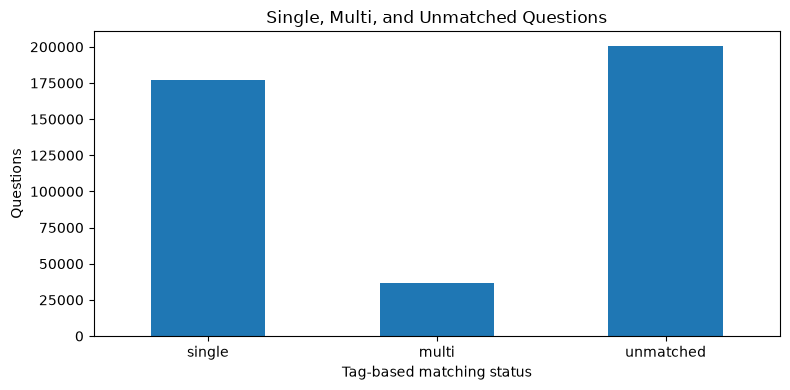

In [4]:
ax = coverage.plot.bar(x="Status", y="Questions", legend=False, figsize=(8,4),
                       title="Single, Multi, and Unmatched Questions")
ax.set(xlabel="Tag-based matching status", ylabel="Questions")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 5. Per-Category Coverage

Break down each category by total matches, exclusive matches, accepted-answer metadata, and answered-question rates.

In [5]:
category_rows=[]
for category in TAXONOMY:
    total=result["any_match"][category]
    accepted=result["accepted_by_category"][category]
    answered=result["answered_by_category"][category]
    category_rows.append({"Category":category,"Any Match":total,
       "Exclusive Match":result["exclusive"][category],
       "Accepted Answers":accepted,"Answered Questions":answered,
       "Accepted Rate (%)":round(100*accepted/total,2) if total else 0,
       "Answered Rate (%)":round(100*answered/total,2) if total else 0})
categories=pd.DataFrame(category_rows)
display(categories)
assert categories["Exclusive Match"].sum() == s["single"]

,Category,Any Match,Exclusive Match,Accepted Answers,Answered Questions,Accepted Rate (%),Answered Rate (%)
0,Network & Connectivity,40665,30107,10873,28923,26.74,71.13
1,Boot & Startup,46090,27048,11677,33414,25.34,72.50
2,Software & Packages,52876,43585,18771,42592,35.50,80.55
3,Hardware & Drivers,60308,43777,15074,41856,25.00,69.40
4,Storage & Filesystems,32105,17841,10206,24406,31.79,76.02
5,Access & Permissions,20603,14836,7306,16096,35.46,78.12


## 6. Class Balance

Visualize the distribution of single-category questions across the six categories to assess class imbalance.

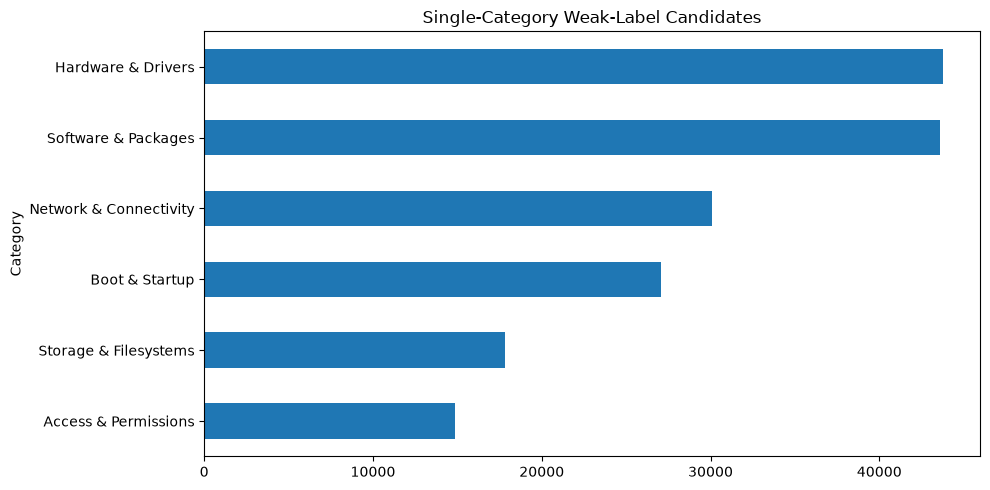

In [6]:
ax = categories.sort_values("Exclusive Match").plot.barh(
    x="Category",y="Exclusive Match",legend=False,figsize=(10,5),
    title="Single-Category Weak-Label Candidates")
plt.tight_layout()
plt.show()

## 7. Category Overlap

Examine which categories co-occur most frequently.

Full overlap patterns count each question once; pairwise counts may count one question in several pairs.

In [7]:
patterns=pd.DataFrame(result["overlap_patterns"].most_common(),
                      columns=["Category Combination","Questions"])
pairs=pd.DataFrame([{"Category A":a,"Category B":b,"Questions":n}
                    for (a,b),n in result["pairwise_overlap"].most_common()])
display(patterns.head(20))
display(pairs.head(20))
assert patterns["Questions"].sum() == s["multi"] if not patterns.empty else s["multi"] == 0

,Category Combination,Questions
0,Boot & Startup + Storage & Filesystems,8608
1,Hardware & Drivers + Network & Connectivity,6774
2,Boot & Startup + Hardware & Drivers,4405
3,Boot & Startup + Software & Packages,2612
4,Hardware & Drivers + Software & Packages,1923
5,Access & Permissions + Storage & Filesystems,1528
6,Access & Permissions + Software & Packages,1383
7,Hardware & Drivers + Storage & Filesystems,1376
8,Network & Connectivity + Software & Packages,1245
9,Software & Packages + Storage & Filesystems,1028


,Category A,Category B,Questions
0,Boot & Startup,Storage & Filesystems,9835
1,Hardware & Drivers,Network & Connectivity,7182
2,Boot & Startup,Hardware & Drivers,5435
3,Boot & Startup,Software & Packages,3419
4,Hardware & Drivers,Software & Packages,2406
5,Hardware & Drivers,Storage & Filesystems,2035
6,Access & Permissions,Storage & Filesystems,1868
7,Software & Packages,Storage & Filesystems,1607
8,Access & Permissions,Software & Packages,1525
9,Network & Connectivity,Software & Packages,1480


## 8. Tag Distribution Within Categories

Inspect which selected tags contribute most to each category, and review the most common tags across the full dataset.

In [8]:
selected_tags=pd.DataFrame([
    {"Category":category,"Tag":tag,"Questions":count}
    for category,counts in result["selected_tag_counts"].items()
    for tag,count in counts.most_common()])
display(selected_tags.groupby("Category",group_keys=False).head(8))
display(pd.DataFrame(result["global_tags"].most_common(25),
                     columns=["Tag","Questions"]))

,Category,Tag,Questions
0,Software & Packages,apt,17505
1,Software & Packages,package-management,10496
2,Software & Packages,upgrade,9634
3,Software & Packages,software-installation,8891
4,Software & Packages,updates,7108
5,Software & Packages,installation,6333
6,Software & Packages,dpkg,4151
7,Software & Packages,dependencies,2898
12,Access & Permissions,permissions,7500
13,Access & Permissions,login,4486


,Tag,Questions
0,boot,24058
1,networking,22985
2,command-line,22509
3,14.04,20403
4,drivers,18196
5,dual-boot,17658
6,apt,17505
7,16.04,17210
8,12.04,16604
9,server,16499


## Findings

### Coverage

- **177,194 questions** (42.75%) match exactly one category.
- **36,568 questions** (8.82%) match multiple categories.
- **200,689 questions** (48.42%) are unmatched.
- Unmatched questions are not automatically out-of-domain and are not assigned an Other label.

### Class Balance

- Exclusive counts range from **14,836** (Access & Permissions) to **43,777** (Hardware & Drivers), a ratio of approximately 3:1.
- Class imbalance will need to be addressed during model evaluation.

### Category Overlap

- The largest pairwise overlap is **Boot & Startup + Storage & Filesystems** (9,835 questions), reflecting the natural relationship between disk and boot issues.
- Multi-category questions are preserved for ambiguity and confidence analysis rather than forced into a single label.

### Answer Availability

- Accepted-answer metadata rates range from 25% (Hardware & Drivers) to 35.5% (Software & Packages).
- These are counts of populated AcceptedAnswerId fields, not verified solutions.

### Limitations

- Tag-based labels are weak labels: a tag match does not guarantee the question truly belongs to that category, and absence of a tag does not prove it does not.
- Illustrative inspection revealed semantic edge cases (e.g., a question about Empathy reconnecting matching Boot & Startup through the "startup" tag).
- Broader human review is needed before treating these labels as training ground truth.
- Tags must not be included as classifier input features, as this would introduce target leakage.


